# Week 4：PyTorch 基础 + 表格 MLP

目标：
1. 理解 tensor、autograd、nn.Module、Dataset/DataLoader、训练循环、早停；
2. 做一个表格 MLP，预测 Response；
3. 训练集再切验证集做早停，测试集只评估一次；
4. 与第 2 周的 RF/Logistic 基线比较；
5. 结果追加到 results/baseline_metrics.csv。

注：运行前需先安装pyTorch（只需一次）
anaconda powershell prompt运行
cd “你的路径”
conda activate ctlearn
pip install torch --index-url https://download.pytorch.org/whl/cpu

In [1]:
# 导入依赖，固定随机种子
from pathlib import Path
import random
import numpy as np
import pandas as pd

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 预处理与评价
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    confusion_matrix,
    roc_curve,
)
from sklearn.calibration import calibration_curve

import matplotlib.pyplot as plt

# 固定随机种子，尽量让每次运行结果一致
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 有 GPU 就用 GPU，没有就用 CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch:", torch.__version__)
print("device:", DEVICE)

torch: 2.15.0+cpu
device: cpu


In [2]:
# Pytorch基础自测
# tensor + autograd 的最小例子
# 这是一段最小可运行的自动微分(autograd)示例，对应了神经网络训练的核心步骤：loss.backward()如何计算梯度

#创建需要求导的张量，resquires_grad = True是指：请跟踪对x的所有操作，之后要对它求梯度
#此时x是一个叶子张量(leaf tensor)，且：
#x.requires_grad   # True   一般默认False，只有手动设为True的张量才会被求导
#x.grad            # None（还没反向传播）
#x.is_leaf         # True
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

#前向求导
#逐元素平方再求和
#由于x.requires_grad=True，因此PyTorch会动态记录这些运算，构建计算图
#x  ──►  x²  ──►  sum  ──►  y
#     (PowBackward)  (SumBackward)
#y不是用户直接创建的叶子，而是运算结果，故：
#y.requires_grad   # True（继承自 x）
#y.grad_fn         # <SumBackward0>（记录了它是怎么算出来的）
#y.is_leaf         # False
y = (x ** 2).sum()

#反向传播
#这是反向模式自动微分(reverse-mode autodiff)，即反向传播
#沿着计算图从y往回走，使用链式法则计算dy/dx，推导出dy/dxi=2xi
#代入得到x=[1,2,3]，dy/dx=[2,4,6]，梯度被写入x.grad
#注：y为标量故可以直接调用y.backward，如果为向量，则需要传入一个与y同形状的gradient参数，指定每个输出分量的权重
y.backward()

print("x:", x)
print("y:", y.item())
print("dy/dx:", x.grad)   # 应该是 2x = [2, 4, 6]

x: tensor([1., 2., 3.], requires_grad=True)
y: 14.0
dy/dx: tensor([2., 4., 6.])


# 1. 叶子张量(leaf tensor)
是指用户自行创建的，并非中间运算产生的张量
叶子节点                中间节点                 根节点
   x        ──►       x²        ──►        sum        ──►  y
（你创建的）          （运算结果）          （运算结果）
PyTorch默认只把梯度保存在叶子张量的 .grad中
# 2. 链式法则
dy/dx = （dy/du） · （du/dx）
多路径时：梯度相加，即一个变量在计算图中被用多次时(出现在两条路径上)，反向传播时，所有路径的梯度在叶子处相加
因此由于链式法则，每一层只需要知道自己的局部导数，将上游传下来的梯度×局部导数，再传给下游，即可实现自动微分
# 3. x.grad
是张量的一个属性，存放目标函数对x的梯度，即保存dy/dx
注意：x.grad存放梯度是累加的，而非覆盖的
如上述代码，如果计算2次y.backward()，得到的结果会是[4,8,12]
因此训练循环时必须清零：optimizer.zero_grad()

In [3]:
# 读取数据、切分训练/验证/测试
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(ROOT / "data/raw/chowell_train.csv")
test = pd.read_csv(ROOT / "data/raw/chowell_test.csv")

TARGET = "Response (1:Responder; 0:Non-responder)"

NUMERIC_FEATURES = [
    "Age",
    "Sex (1:Male; 0:Female)",
    "BMI",
    "Stage (1:IV; 0:I-III)",
    "NLR",
    "Platelets",
    "HGB",
    "Albumin",
    "Drug (1:Combo; 0:PD1/PDL1orCTLA4)",
    "TMB",
    "FCNA",
    "HED",
    "HLA_LOH",
    "MSI (1:Unstable; 0:Stable_Indeterminate)",
    "MSI_SCORE",
    "Chemo_before_IO (1:Yes; 0:No)",
]

CATEGORICAL_FEATURES = ["Cancer_type_grouped_2"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_all_train = train[FEATURES].copy()
y_all_train = train[TARGET].astype(int).values

X_test = test[FEATURES].copy()
y_test = test[TARGET].astype(int).values

# 从训练集里再切 20% 做验证集，用于早停；
# 测试集完全不参与训练和早停。
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all_train,
    y_all_train,
    test_size=0.2,
    stratify=y_all_train,
    random_state=SEED,
)

print("train:", X_tr.shape, "val:", X_val.shape, "test:", X_test.shape)
print("positive rate — train: %.4f, val: %.4f, test: %.4f" % (
    y_tr.mean(), y_val.mean(), y_test.mean()
))

train: (947, 17) val: (237, 17) test: (295, 17)
positive rate — train: 0.2693, val: 0.2700, test: 0.3051


In [4]:
# 预处理，仅在训练集fit
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), #模型学习中位数
    ("scaler", StandardScaler()),#模型学习均值和标准差
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),#学习众数
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),#学习训练集中的类别列表和顺序
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC_FEATURES),
    ("cat", categorical_pipe, CATEGORICAL_FEATURES),
], remainder="drop")

# 只在训练集上 fit，验证集/测试集只 transform
X_tr_np = preprocessor.fit_transform(X_tr).astype(np.float32)
X_val_np = preprocessor.transform(X_val).astype(np.float32)
X_test_np = preprocessor.transform(X_test).astype(np.float32)

print("input dim:", X_tr_np.shape[1])

input dim: 32


fit：是指模型学习数据
transform：是指用模型学到的数据再回过头去处理数据
例如：
X_tr_np = preprocessor.fit_transform(X_tr).astype(np.float32)
是指再训练集学习到中位数、均值、标准差、类别列表后，再用学到的数据去处理训练集中的缺失值

X_val_np = preprocessor.transform(X_val).astype(np.float32)
X_test_np = preprocessor.transform(X_test).astype(np.float32)
由于要防止数据泄露，故对验证集和测试集不进行fit学习(不看它们的数据),而是直接用再训练集学习到的值去处理这两个数据集中的缺失值

In [5]:
#构建Dataset和DataLoader

#本部分目的是将Numpy数组包装为PyTorch可以高效迭代的Dataset+DataLoader
#训练时每次取一小批(64条)样本做前向、反向、更新，而非一次性喂全部数据

#每个mini-batch包含64个样本
#一个epoch(完整遍历一次训练集)会被切成若干个batch
BATCH_SIZE = 64
#使用mini-batch的原因：
#    比全量梯度下降更新的更频繁、收敛更快
#    比单样本SGD更稳定，能利用矩阵运算加速
#    64/128/256是常用取值，受内存和样本的影响


# TensorDataset 是最简单的 Dataset：把特征和标签一一对应
#训练集
#将特征张量和标签张量按照"第一维对齐"打包，即第i个样本为(特征[i]，标签[i])，这要求两个张量第一个维度(947)相同
train_ds = TensorDataset(
     #将Numpy特征矩阵(947, 17)转成PyTorch张量
    torch.tensor(X_tr_np, dtype=torch.float32),
    #将Numpy标签矩阵(947,)转成PyTorch张量
    #使用.view(-1,1)把形状(947,)变成(947, 1)，-1表示这一维自动推断(此处推断为947)，
    #此处目的是使标签保持同形状，防止loss计算出问题
    torch.tensor(y_tr, dtype=torch.float32).view(-1, 1),
)

#验证集/测试集
val_ds = TensorDataset(
    torch.tensor(X_val_np, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32).view(-1, 1),
)
test_ds = TensorDataset(
    torch.tensor(X_test_np, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32).view(-1, 1),
)

#注：用BCEWithLogitsLoss / BCELoss计算loss时需要view(1,-1)，防止形状不匹配导致报错
#    如果用CrossEntropyLoss损失函数，需要dtype=torch.long, 形状(batch,)，无需view(-1,1)


#按照批次迭代构建DataLoader
# 训练集 shuffle=True；验证/测试集不 shuffle
# shuffle=True的原因：如果数据按照类别/时间排序，不打乱会让每个batch的分布偏倚，打乱以后更接近整体分布，梯度估计更稳，也可以避免模型学到"样本顺序"这种虚假规律
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True, #每个epoch重新打乱样本顺序
    generator=torch.Generator().manual_seed(SEED), #固定打乱的随机种子，保证可复现
)
#验证集/测试集的评估指标与顺序无关，打乱没有收益；且固定顺序便于把预测结果和原始标签逐条对齐；减少不确定性，使结果可复现
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

#len(loader)返回batch的数量
print("batches — train:", len(train_loader), "val:", len(val_loader), "test:", len(test_loader))

batches — train: 15 val: 4 test: 5


In [6]:
#定义MLP模型、损失函数、优化器，详细内容见学习笔记相关部分
#这一部分定义了一个用于表格数据的3层MLP，并配置好：
#输入(32维)→64→32→1(logit)
#损失函数BCEWithLogitsLoss + pos_weight（处理 27% 的不平衡）
#优化器：Adam(lr=1e-3, weight_decay=1e-4)

#总体任务：配置好小型MLP，输出原始logit，再用pos_weight≈2.712的BCEWithLogitsloss缓解阳性只占27%的不平衡，最后用Adam优化

#继承nn.Module
#nn.Modle是所有神经网络模块的基类/管理器，继承后自动获得：————其他部分是乐高积木，那么nn.Module就是底板
#   参数注册与管理(model.parameters())
#   前向调用model(x)的能力
#   train()/eval()模式切换
#   state_dirc()保存/加载权重
#   .to(device)搬移参数
class TabularMLP(nn.Module):
    """
    简单的表格 MLP：
    输入 -> 64 -> 32 -> 1
    隐藏层用 ReLU + Dropout；最后一层输出 logit，不加 sigmoid。
    """

    #初始化父类，否则PyTorch无法注册子模块
    #参数含义：
    #    input_dim是输入特征数，即之前prep中fit_transform的X_tr_np，预处理后是32
    #    hidden1=64，第一隐藏层的宽度
    #    hidden2=32，第二隐藏层的宽度
    #    dropout=0.3，每个Dropout层丢弃30%神经元
    def __init__(self, input_dim, hidden1=64, hidden2=32, dropout=0.3):
        super().__init__()

        #nn.Sequential堆叠网络，是一个"容器"，按照顺序执行里面的层，输入的x会依次流过每一层
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden1), #形状(B,32)(B,64)，全连接y=x·W^T+b
            nn.ReLU(), #形状不变，非线性max(0,x)，没有ReLU，那么两层Linear叠加等价于一层Linear，网络会退化为线性模型，ReLU引入非线性，使MLP能拟合复杂关系
            nn.Dropout(dropout),#形状不变，训练时随机把30%的元素置0，防止过拟合；注意model.eval()会不丢弃而原样通过，故训练和评估前需正确切换model.train()/model.eval()
            nn.Linear(hidden1, hidden2),#形状变为(B,64)(B,32)，是第二个隐藏层
            nn.ReLU(),#形状不变，非线性
            nn.Dropout(dropout),#同上
            nn.Linear(hidden2, 1),#形状变为(B,32)(B,1)，输出1个logit(未归一化的分数，二分类只需1个输出)，配合BCEWithLogitLoss使用(该损失函数内部自带sigmoid，且数值更稳定)
        )

    #定义数据如何流经网络
    #调用时用model(x)，而非model.forward(x)——__call__会额外处理hooks等机制
    #输入x形状(B,32),输出(B,1)
    def forward(self, x):
        return self.net(x)

#实例化模型
#X_tr_np是预处理后的矩阵，本数据为16个数值特征+16个癌种的one-hot=32维
#.to(DIVICE)把模型所有参数搬到DEVICE(本机器为CPU)，如果有GPU就搬到显存
#注意输入数据也要.to(DEVICE)，否则会报"device mismatch"
model = TabularMLP(input_dim=X_tr_np.shape[1]).to(DEVICE)
print(model)


# 阳性只占约 27%，用 pos_weight 让损失函数更关注阳性
# 使模型更愿意预测阳性，提高Recall，但是Precision可能下降
pos_weight = torch.tensor(
    [(y_tr == 0).sum() / (y_tr == 1).sum()],
    dtype=torch.float32,
    device=DEVICE,
)

# 损失函数BCEWithLogitsLoss 内部包含 sigmoid，输入必须是 logit
# target必须是float，形状(B,1)，与view(-1,1)的处理相对应
# 输出logit的形状，(B,1)，与target对齐
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)


#配置优化器Adam
optimizer = torch.optim.Adam(
    model.parameters(), #所有需要梯度的叶子张量(权重、偏置)
    lr=1e-3, #学习率0.001，Adam的常用默认值
    weight_decay=1e-4, #L2正则，一致权重过大，防止过拟合，此处使耦合式L2，更现代的做法是AdamW
)

print("pos_weight:", float(pos_weight.item()))

TabularMLP(
  (net): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
pos_weight: 2.7137255668640137


In [7]:
# 训练循环+验证集早停
#本部分为标准的PyTorch训练循环
#每个epoch：
#每个 epoch：
#  ① 训练：遍历 train_loader，前向 → 算 loss → 反向 → 更新参数
#  ② 验证：遍历 val_loader，只前向、不更新，算 loss 和 AUROC
#  ③ 记录：把 train_loss / val_loss / val_auc 存进 history
#  ④ 早停：验证 AUROC 连续 20 轮不提升就停止，并恢复最好的参数


#设置超参数与状态变量(关于超参数是什么详见笔记)
EPOCHS = 200           #最多训练200轮
PATIENCE = 20          # 验证集 AUROC 连续 20 轮不提升就停止

best_val_auc = -np.inf  #目前见过的最好验证AUROC，初始为负无穷
best_state = None       #最好那一轮的模型参数副本
patience_counter = 0    #已经连续多少轮没有提升

history = {             #用字典保存每一轮的指标，训练结束后可以画学习曲线(loss下降、AUROC上升等)
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_auc": [],
}

#训练阶段
for epoch in range(1, EPOCHS + 1):
    # ---------- 训练 ----------
    model.train() #开始训练模式，Dropout生效，这是nn.Module的递归开关，会作用到所有子层
    train_loss_sum = 0.0 

#每次从train_loader取一个batch(64条，最后一个51条)
    for xb, yb in train_loader:
        xb = xb.to(DEVICE) #.to(DEVICE)是指把数据搬到模型所在设备，注意模型与数据必须同一设备，否则报错
        yb = yb.to(DEVICE)

        #清空上一轮梯度，因为pytorch梯度是累加的，不清空会越加越多
        optimizer.zero_grad()

        #训练的核心4步
        logits = model(xb) #前向传播，算预测分数
        loss = criterion(logits, yb) #计算损失(即预测与真实标签的差距)，BCEWithLogitsLoss + pos_weight
        loss.backward() #反向传播，算出每个参数的梯度
        optimizer.step() #更新参数，按照Adam规则微调权重

        # 按样本数加权，得到整个 epoch 的平均 loss(因为最后一个只有51个batch，直接求平均会高估小batch的权重)
        train_loss_sum += loss.item() * xb.size(0)

    #得到每个样本的平均loss，即这一个epoch中的loss值
    train_loss = train_loss_sum / len(train_ds)

    # ---------- 验证 ----------
    model.eval()  #切换到评估模式，Dropout关闭
    val_loss_sum = 0.0
    val_probs = []

    with torch.no_grad(): #关闭梯度计算，因为验证不需要反向传播
        for xb, yb in val_loader:
            #取验证batch(237条分成4批)
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            #前向算logits和loss，不反向、不更新
            logits = model(xb)
            loss = criterion(logits, yb)
            val_loss_sum += loss.item() * xb.size(0)

            #将原始分数转为0~1概率，并搬到CPU转成NUmpy数组，方便sklearn计算
            val_probs.append(torch.sigmoid(logits).cpu().numpy())

    val_loss = val_loss_sum / len(val_ds)
    val_probs = np.concatenate(val_probs).ravel() #将4个batch的概率拼成1个数组，.ravel()将(237,1)压成(237,)
    val_auc = roc_auc_score(y_val, val_probs) #计算验证集AUROC

    #将本轮指标存入history，方便之后画曲线
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_auc"].append(val_auc)

    print(
        f"epoch {epoch:03d} | "
        f"train loss {train_loss:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"val AUROC {val_auc:.4f}"
    )

    # ---------- 早停 ----------
    if val_auc > best_val_auc + 1e-4: #只有比历史最好值高出0.0001才算有提升，加0.0001目的是过滤掉微小的随机波动，避免被噪声影响一致训练
        best_val_auc = val_auc
        # 保存验证集最好的模型参数（复制到 CPU，避免后续更新影响）
        best_state = {
            k: v.detach().cpu().clone() #detach()从计算图中分离 .cpu()搬到CPU .clone复制一份
            for k, v in model.state_dict().items() #state_dict()将参数名转为张量
        }
        patience_counter = 0 #重置耐心计数
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE: #连续20轮没有提升就打印并跳出训练
            print(f"early stopping at epoch {epoch}")
            break

# 恢复验证集最好的参数(因为早停时已经训练到开始变差的状态了，因此需要重新加载回来验证集表现最好的一轮参数)
if best_state is not None:
    model.load_state_dict(best_state)

print("best val AUROC:", round(best_val_auc, 4))

epoch 001 | train loss 1.0108 | val loss 0.9990 | val AUROC 0.6693
epoch 002 | train loss 1.0005 | val loss 0.9822 | val AUROC 0.7074
epoch 003 | train loss 0.9831 | val loss 0.9664 | val AUROC 0.7235
epoch 004 | train loss 0.9657 | val loss 0.9424 | val AUROC 0.7333
epoch 005 | train loss 0.9473 | val loss 0.9180 | val AUROC 0.7355
epoch 006 | train loss 0.9400 | val loss 0.8976 | val AUROC 0.7378
epoch 007 | train loss 0.9261 | val loss 0.8867 | val AUROC 0.7337
epoch 008 | train loss 0.9213 | val loss 0.8790 | val AUROC 0.7393
epoch 009 | train loss 0.9004 | val loss 0.8738 | val AUROC 0.7377
epoch 010 | train loss 0.8897 | val loss 0.8710 | val AUROC 0.7368
epoch 011 | train loss 0.8965 | val loss 0.8695 | val AUROC 0.7409
epoch 012 | train loss 0.8891 | val loss 0.8691 | val AUROC 0.7408
epoch 013 | train loss 0.8810 | val loss 0.8621 | val AUROC 0.7445
epoch 014 | train loss 0.8732 | val loss 0.8593 | val AUROC 0.7485
epoch 015 | train loss 0.8761 | val loss 0.8579 | val AUROC 0.

In [8]:
# 测试集评估 + bootstrap 95%CI
#主要是用训练好的MLP在测试集上做最终评估
#  ① predict_probs：遍历 test_loader，输出每个样本的阳性概率
#  ② 按 0.5 阈值转成 0/1 预测
#  ③ 计算 AUROC / AUPRC / Accuracy 的点估计
#  ④ 用 bootstrap 给三个指标各算 95% 置信区间
#  ⑤ 打印指标 + 混淆矩阵


def predict_probs(model, loader):
    """返回整个 loader 的预测概率。"""
    model.eval() #切换到评估模式，如果不切则每次评估结果都不相同
    probs = [] #用来收集每个batch的概率数组

    with torch.no_grad(): #关闭梯度计算，评估不需要反向传播
        for xb, _ in loader: #只需要特征xb，标签用_忽略(因为后面直接用y_test)
            xb = xb.to(DEVICE)
            logits = model(xb) #前向传播，得到原始分数logit，形状为(batch_size, 1)
            probs.append(torch.sigmoid(logits).cpu().numpy())

    return np.concatenate(probs).ravel() #返回长度等于测试集样本数的一维概率数组


def bootstrap_ci(y_true, y_prob, metric_fn, n_boot=1000, seed=SEED): #参数分别为：真实标签、预测概率、要计算的指标函数、重采样次数、随机种子保证可复现
    """按样本有放回重采样，返回 metric 的 2.5% 和 97.5% 分位数。"""
    #创建局部随机数生成器，固定种子并转成numpy数组
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    n = len(y_true)

    #有放回地从[0,n)中抽n个索引，yt、yp构成伪测试集
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt, yp = y_true[idx], y_prob[idx]

        # 重采样后如果只剩一个类别，AUROC 无法计算，直接跳过这次重采样
        if len(np.unique(yt)) < 2:
            continue

        #在伪测试集上算一次指标并收集起来
        values.append(metric_fn(yt, yp))

    #取1000个指标的2.5%和97.5%分位数得到95%置信区间
    return np.percentile(values, [2.5, 97.5])

#三个指标包装函数，包装的目的是统一接口，因为bootstrap_ci要求指标函数只接受(y_true, y_prob)两个参数
def auroc_fn(y_true, y_prob):
    return roc_auc_score(y_true, y_prob)


def auprc_fn(y_true, y_prob):
    return average_precision_score(y_true, y_prob)


def accuracy_fn(y_true, y_prob, threshold=0.5): #accuracy不能直接吃概率，必须先按照阈值转成0/1
    return accuracy_score(y_true, (y_prob >= threshold).astype(int))


#主流程
y_prob_test = predict_probs(model, test_loader) #测试集每个样本的阳性概率，形状(295,)
y_pred_test = (y_prob_test >= 0.5).astype(int)

#3个点估计
auroc = roc_auc_score(y_test, y_prob_test)
auprc = average_precision_score(y_test, y_prob_test)
acc = accuracy_score(y_test, y_pred_test)
#3个置信区间
#由于三次调用同一个SEED，所以重采样索引完全相同，可以直接横向比较
auroc_ci = bootstrap_ci(y_test, y_prob_test, auroc_fn)
auprc_ci = bootstrap_ci(y_test, y_prob_test, auprc_fn)
acc_ci = bootstrap_ci(y_test, y_prob_test, accuracy_fn)

print("MLP test")
print(f"  AUROC : {auroc:.4f}  (95% CI {auroc_ci[0]:.4f}–{auroc_ci[1]:.4f})")
print(f"  AUPRC : {auprc:.4f}  (95% CI {auprc_ci[0]:.4f}–{auprc_ci[1]:.4f})")
print(f"  Acc   : {acc:.4f}  (95% CI {acc_ci[0]:.4f}–{acc_ci[1]:.4f})")
print("  Confusion matrix:")
print(confusion_matrix(y_test, y_pred_test))

MLP test
  AUROC : 0.7702  (95% CI 0.7143–0.8275)
  AUPRC : 0.6052  (95% CI 0.5176–0.7027)
  Acc   : 0.7051  (95% CI 0.6542–0.7525)
  Confusion matrix:
[[144  61]
 [ 26  64]]


最后的混淆矩阵：
| 位置 | 含义 |
|---|---|
| 左上 TN | 实际阴性，预测阴性 |
| 右上 FP | 实际阴性，预测阳性（误报） |
| 左下 FN | 实际阳性，预测阴性（漏报） |
| 右下 TP | 实际阳性，预测阳性 |

结果解读：
与前面模型相比：
AUROC:       RF > LR > MLP ≈ XGB
AUPRC:       RF > XGB > MLP > LR
Accuracy:    RF > XGB > LR > MLP > Dummy
Recall:      MLP > LR > RF > XGB
Precision:   XGB ≈ RF > LR > MLP

说明：
1. MLP各指标比Dummy高，说明MLP确实学到了东西
2. MLP并没有高于RF指标，说明数据信号确实以线性/可加关系为主
3. MLP的Recall最高，Precision最低，说明MLP最“激进”，宁可报错也不漏报，代价是假阳性变多
4. 由于各个模型的AUROC和AUPRC的CI均有重叠，故不能断言某个显著由于另一个，需要做配对bootstrap

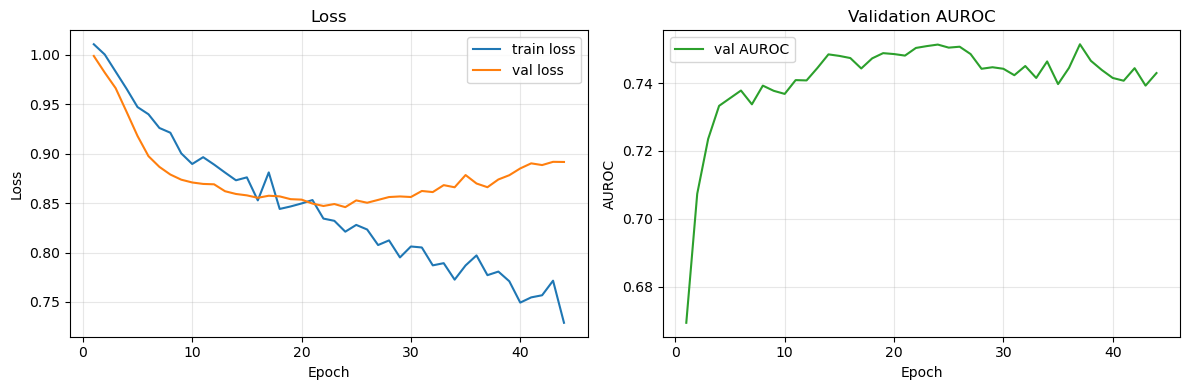

In [9]:
#训练曲线
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss 曲线
axes[0].plot(history["epoch"], history["train_loss"], label="train loss")
axes[0].plot(history["epoch"], history["val_loss"], label="val loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 验证集 AUROC 曲线
axes[1].plot(history["epoch"], history["val_auc"], label="val AUROC", color="tab:green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUROC")
axes[1].set_title("Validation AUROC")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "w04_training_curve.png", dpi=300, bbox_inches="tight")
plt.show()

结果解读：
# 1. 左图：Loss曲线
| 现象 | 解读 |
|---|---|
| 前 10 轮两条线一起快速下降 | 模型在有效学习，信号真实存在 |
| **第 18~20 轮左右两条线交叉** | 之后 train loss 持续下降，但 val loss 开始上升 |
| 第 45 轮时差距约 **0.16** | 典型的**过拟合**：模型开始"背训练集" |
| val loss 最低点约在第 25 轮 | 这一带是泛化最好的区间 |

因此：模型大约20~25轮开始过拟合，早停在45轮触发，说明验证集AUROC已经连续20轮没有实质提升，最终恢复的是最佳轮次(约第25轮)的权重

# 2. 右图：验证集AUROC曲线
| 现象 | 解读 |
|---|---|
| **前 5 轮飙升** | 模型很快抓住了主要信号 |
| **第 15 轮后进入平台** | 继续训练几乎没有提升 |
| 平台期上下波动约 ±0.005 | 验证集只有 237 条，噪声导致抖动 |
| 第 45 轮 ≈ 0.745 | 略低于峰值 |

与测世界AUROC 0.770相比，测试集略高于验证集，但差距在抽样误差内

# 3. val loss上升但AUROC没降
| 指标 | 衡量什么 |
|---|---|
| **val loss（BCE）** | 预测概率是否**校准**、是否过度自信 |
| **val AUROC** | 只衡量**排序**能力 |
因此可能出现，模型排序能力还在，但是预测概率越来越极端，导致BCE loss上升
这也与pos_weight ≈ 2.7有关，会把阳性概率提高，进一步影响校准

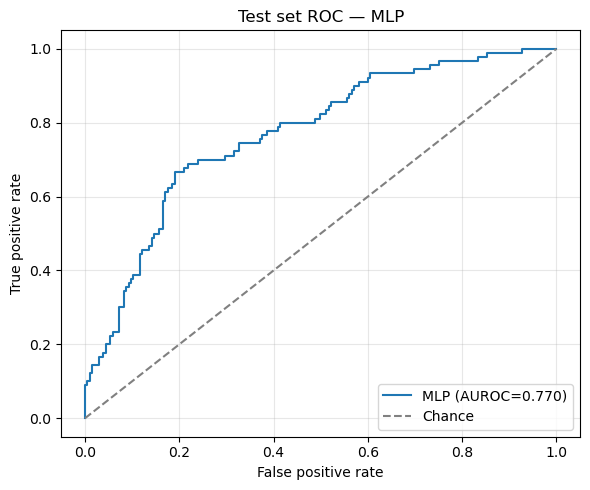

In [10]:
# 测试ROC曲线
fig, ax = plt.subplots(figsize=(6, 5))

fpr, tpr, _ = roc_curve(y_test, y_prob_test)
ax.plot(fpr, tpr, label=f"MLP (AUROC={auroc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test set ROC — MLP")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "w04_mlp_roc.png", dpi=300, bbox_inches="tight")
plt.show()

这张 ROC 图显示 MLP 在测试集上的 AUROC = 0.770：曲线全程高于随机线，前段较陡（FPR 15% 可抓 60% 阳性），中段出现平台，尾部要牺牲大量特异度才能把召回推到 90% 以上。
0.5 阈值对应的工作点是 FPR≈30%、Recall≈71%，属于"偏向多报、少漏报"的策略。
整体区分能力中等，与 XGBoost 持平、低于 RF/LR，但差距在置信区间内；
由于 ROC 不反映校准和类别不平衡，建议再结合 AUPRC（0.605）和校准曲线一起看。

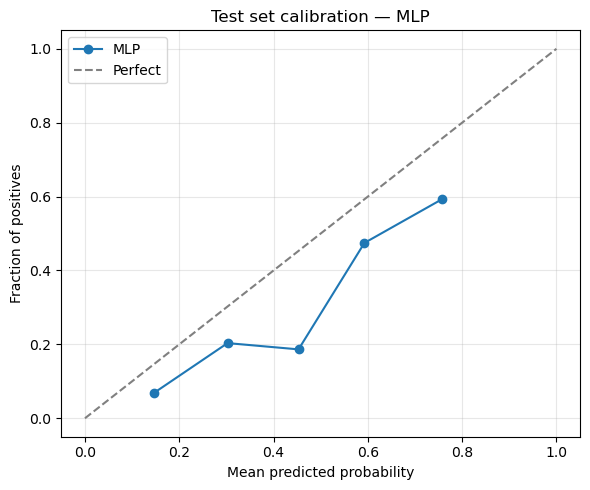

In [11]:
# 测试集校准曲线
fig, ax = plt.subplots(figsize=(6, 5))

frac_pos, mean_pred = calibration_curve(
    y_test,
    y_prob_test,
    n_bins=5,
    strategy="quantile",
)

ax.plot(mean_pred, frac_pos, marker="o", label="MLP")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect")

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Test set calibration — MLP")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(RESULTS / "w04_mlp_calibration.png", dpi=300, bbox_inches="tight")
plt.show()

结果解读：
| 元素 | 含义 |
|---|---|
| 横轴 | 每个分箱内的**平均预测概率**（模型“说”的概率） |
| 纵轴 | 每个分箱内的**实际阳性比例**（真实发生的比例） |
| 灰色虚线 | **完美校准线**：预测 = 实际 |
| 蓝色折线 | MLP 的实际表现 |
| 分箱方式 | `n_bins=5`、`strategy="quantile"`，每箱约 59 人 |

总体来看，曲线在虚线下方，说明模型高估了阳性概率，原因：
pos_weight ≈ 2.7、类别不平衡、样本量太小导致的误差

模型排序能力尚可（AUROC 0.77），但概率数值不可直接当真实风险使用；若要用于风险沟通或成本决策，应在验证集上做 Platt/Isotonic 校准，或者干脆去掉 pos_weight、改用阈值调节。

In [14]:
# 与第2周的4个基线模型作比较
# 直接读取 week02 已保存的基线结果，不再重跑 week2 代码
# 运行本 cell 前，请先运行上面的“测试集评估 + bootstrap 95%CI” cell

# 兼容两种文件名：优先 w02_baseline_metrics.csv，其次 baseline_metrics.csv
BASELINE_CANDIDATES = [
    RESULTS / "w02_baseline_metrics.csv",
    RESULTS / "baseline_metrics.csv",
]
baseline_path = next((p for p in BASELINE_CANDIDATES if p.exists()), None)
if baseline_path is None:
    raise FileNotFoundError(
        "未找到基线结果，请确认 results/ 下存在 w02_baseline_metrics.csv 或 baseline_metrics.csv"
    )

baseline_df = pd.read_csv(baseline_path)
print("loaded:", baseline_path, baseline_df.shape)

# 如果读到的文件已经包含 MLP（例如重复运行），先去掉旧 MLP 行，保证可重复执行
baseline_df = baseline_df[baseline_df["model"] != "MLP"].copy()

# 把当前 MLP 的测试结果整理成同样的长表格式
mlp_rows = []
for metric_name, metric_value, metric_ci in [
    ("auroc", auroc, auroc_ci),
    ("auprc", auprc, auprc_ci),
    ("accuracy", acc, acc_ci),
]:
    mlp_rows.append({
        "model": "MLP",
        "endpoint": "Response",
        "split": "test",
        "metric": metric_name,
        "value": metric_value,
        "ci_low": metric_ci[0],
        "ci_high": metric_ci[1],
        "notes": "test set; 1000x bootstrap 95% CI",
    })

mlp_df = pd.DataFrame(mlp_rows)

# 合并：week02 基线 + MLP；写入 results/baseline_metrics.csv
combined_df = pd.concat([baseline_df, mlp_df], ignore_index=True)
combined_path = RESULTS / "w04_baseline_metrics.csv"
combined_df.to_csv(combined_path, index=False, encoding="utf-8-sig")
print("saved:", combined_path)

# 打印测试集横向对比（按 AUPRC 降序；不平衡数据主指标）
test_summary = (
    combined_df[combined_df["split"] == "test"]
    .pivot(index="model", columns="metric", values="value")
    [["auroc", "auprc", "accuracy"]]
    .sort_values("auprc", ascending=False)
)

print("\nTest-set comparison (baseline + MLP):")
print(test_summary.round(4).to_string())

loaded: d:\TJH课题工作内容\clinicaltransformer\studyplan\results\w02_baseline_metrics.csv (24, 8)
saved: d:\TJH课题工作内容\clinicaltransformer\studyplan\results\w04_baseline_metrics.csv

Test-set comparison (baseline + MLP):
metric               auroc   auprc  accuracy
model                                       
RandomForest        0.8055  0.6757    0.7627
XGBoost             0.7708  0.6408    0.7593
MLP                 0.7702  0.6052    0.7051
LogisticRegression  0.7862  0.5967    0.7220
Dummy (prior)       0.5000  0.3051    0.6949


## 结论

- MLP 测试集 AUROC：_0.7702__（95% CI _0.7143–0.8275）
- MLP 测试集 AUPRC：_0.6052__
- Week 2 最佳基线 AUROC：_RF 0.8055__
- MLP 是否超过基线：_无__
- 最佳验证集 AUROC：_0.7514
- 训练曲线是否过拟合：_存在轻度过拟合__

## 本周局限

- 单次 train/val/test 划分，未做交叉验证；
- 未系统调参（隐藏层大小、dropout、学习率）；
- 泛癌种数据，不能直接代表直肠癌；
- 与论文的 Transformer 还有很大差距。

## Week 4 检查点

1. `[Key, Value]` 里的 Key 和 Value 分别怎么变成向量？
2. 为什么论文的 Transformer 不加位置编码？
3. `[TASK]` 和 `[MASK]` 分别在预训练/微调中做什么？
4. 你的 MLP 和 logistic 基线，谁更好？为什么？
5. 从干净 kernel 重跑一遍，能复现你的数字吗？